The Figure 1 scheme:

(a) Ring with 3 sources and 3 sinks,

(b) complete bipartite $K_{3,3}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyBboxPatch, Circle

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42, "svg.fonttype": "none",
})

In [2]:
C_GEN, C_CON = "#1f77b4", "#ff7f0e"
R = 0.21
MM = 1 / 25.4

def draw_node(ax, xy, label, is_source):
    x, y = xy
    if is_source:
        ax.add_patch(FancyBboxPatch((x - R, y - R), 2 * R, 2 * R, boxstyle="square,pad=0", fc=C_GEN, ec="none", zorder=3))
    else:
        ax.add_patch(Circle(xy, R, fc=C_CON, ec="none", zorder=3))
    ax.text(x, y, label, ha="center", va="center", zorder=4, fontsize=6, color="white" if is_source else "black")

def draw_edges(ax, G, pos, labels=None):
    for (u, v) in G.edges():
        (x1, y1), (x2, y2) = pos[u], pos[v]
        ax.plot([x1, x2], [y1, y2], color="k", lw=0.8, zorder=1)
    if labels:
        for (u, v), e in labels.items():
            (x1, y1), (x2, y2) = pos[u], pos[v]
            xm, ym = (x1 + x2) / 2, (y1 + y2) / 2
            ang = np.degrees(np.arctan2(y2 - y1, x2 - x1))
            if ang > 90: ang -= 180
            if ang < -90: ang += 180
            ax.text(xm, ym, rf"$e={e}$", ha="center", va="center", rotation=ang, rotation_mode="anchor", fontsize=6, zorder=2,
                    bbox=dict(fc="white", ec="none", pad=0.6))

def finish(ax, letter):
    ax.set_aspect("equal")
    ax.axis("off")
    ax.text(-0.02, 1.0, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="top", ha="left")

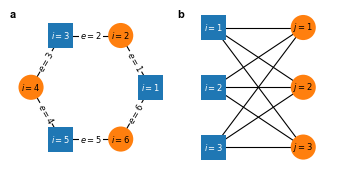

In [3]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(88 * MM, 55 * MM))

# Panel (a) ring, 6 nodes alternating
ring_order = [1, 2, 3, 4, 5, 6]
angles = np.deg2rad(np.arange(6) * 60)
pos_a = {n: (np.cos(a), np.sin(a)) for n, a in zip(ring_order, angles)}
Ga = nx.cycle_graph(ring_order)
edge_lab_a = {(1, 2): 1, (2, 3): 2, (3, 4): 3, (4, 5): 4, (5, 6): 5, (6, 1): 6}
draw_edges(axa, Ga, pos_a, edge_lab_a)
for n, xy in pos_a.items():
    draw_node(axa, xy, rf"$i={n}$", n % 2 == 1)
axa.set_xlim(-1.3, 1.3); axa.set_ylim(-1.3, 1.3)
finish(axa, "a")

# Panel (b) complete bipartite graph K_{3,3}
top, bottom = [1, 3, 5], [2, 4, 6]
ys = [1.0, 0.0, -1.0]                      # squares left, circles right
pos_b = {**{n: (-0.75, y) for n, y in zip(top, ys)},
         **{n: (0.75, y) for n, y in zip(bottom, ys)}}
Gb = nx.Graph([(u, v) for u in top for v in bottom])   # K_{3,3}
SHOW_EDGE_LABELS_B = False                 # 9 crossing edges -> crowded
edge_lab_b = ({e: k + 1 for k, e in enumerate(Gb.edges())}
              if SHOW_EDGE_LABELS_B else None)
draw_edges(axb, Gb, pos_b, edge_lab_b)
for k, n in enumerate(top):
    draw_node(axb, pos_b[n], rf"$i={k+1}$", True)
for k, n in enumerate(bottom):
    draw_node(axb, pos_b[n], rf"$j={k+1}$", False)
axb.set_xlim(-1.3, 1.3); axb.set_ylim(-1.3, 1.3)
finish(axb, "b")

# Save figure
fig.tight_layout(w_pad=1.0)
fig.savefig("Figure1.pdf", bbox_inches="tight")